# Model Evaluation: SVM and Baseline Comparison

**Project:** AI-Based Digital Learning Assistant (digital literacy tutor)
**Dataset:** ASSISTments Skill Builder (`data/raw/skill_builder_data.csv`)
**Companion scripts:** `src/train_svm.py`, `src/experiments.py`

The tutor needs to know how well a student is doing, so the predictive model
estimates whether a problem attempt is correct (`correct` in {0, 1}). This
notebook trains an SVM - the model our teacher asked for - alongside a logistic
regression and the random forest baseline, then evaluates them on several
train/test splits and with cross-validation. All metrics use the shared
definitions in `src/evaluation.py`, and the runs are logged to DAGsHub MLflow.

In [1]:
%matplotlib inline
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow

# Locate the repository root so the notebook runs from either the repo root or notebooks/.
ROOT = os.getcwd()
if not os.path.isdir(os.path.join(ROOT, "src")):
    ROOT = os.path.abspath(os.path.join(ROOT, ".."))
SRC = os.path.join(ROOT, "src")
if SRC not in sys.path:
    sys.path.insert(0, SRC)

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay, classification_report

# Shared metric definitions so the notebook and the DVC pipeline agree.
from evaluation import classification_metrics, positive_scores
from utils import setup_mlflow

RANDOM_STATE = 42
SAMPLE_SIZE = 15000  # keep the notebook quick; src/experiments.py runs the full suite
FEATURES = ["attempt_count", "ms_first_response", "hint_count", "hint_total", "overlap_time", "opportunity"]
TARGET = "correct"

pd.set_option("display.width", 150)
print("Repository root:", ROOT)

Repository root: C:\ML-ops


## 1. Load the data and characterise it

In [2]:
raw = pd.read_csv(os.path.join(ROOT, "data", "raw", "skill_builder_data.csv"), encoding="latin1", low_memory=False)
print("Raw shape:", raw.shape)
print("\nTarget distribution (`correct`):")
print(raw[TARGET].value_counts(dropna=False))
print("\nMissing values in the selected features:")
print(raw[FEATURES].isna().sum())

Raw shape: (525534, 30)

Target distribution (`correct`):
correct
1    357085
0    168449
Name: count, dtype: int64

Missing values in the selected features:
attempt_count        0
ms_first_response    0
hint_count           0
hint_total           0
overlap_time         0
opportunity          0
dtype: int64


In [3]:
# Mirror of src/prepare.py: keep binary targets, coerce features, median-impute.
df = raw[raw[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype(int)
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

print("Modeling rows:", len(df))
print("Positive rate:", round(df[TARGET].mean(), 4))
df[FEATURES + [TARGET]].describe()

Modeling rows: 525534
Positive rate: 0.6795


,attempt_count,ms_first_response,hint_count,hint_total,overlap_time,opportunity,correct
count,525534.000000,5.255340e+05,525534.000000,525534.000000,5.255340e+05,525534.000000,525534.000000
mean,1.502466,4.799217e+04,0.440900,2.343095,5.958873e+04,79.017325,0.679471
std,10.579588,3.186983e+05,1.126559,1.647155,3.424129e+05,271.379609,0.466680
min,0.000000,-7.759575e+06,0.000000,0.000000,-7.759575e+06,1.000000,0.000000
25%,1.000000,7.687000e+03,0.000000,0.000000,9.904000e+03,4.000000,0.000000
50%,1.000000,2.079100e+04,0.000000,3.000000,2.573500e+04,12.000000,1.000000
75%,1.000000,5.000000e+04,0.000000,3.000000,6.232300e+04,46.000000,1.000000
max,3824.000000,8.407692e+07,10.000000,10.000000,8.407692e+07,3585.000000,1.000000


## 2. Train/test splits

The single 80/20 split used by the baseline is not enough to trust the result,
so we define a reusable split function and study three ratios. The training
side is capped by `SAMPLE_SIZE` because kernel SVM cost grows with the number of
rows; the test side always stays complete.

In [4]:
def make_split(test_size, random_state=RANDOM_STATE):
    X_tr, X_te, y_tr, y_te = train_test_split(
        df[FEATURES], df[TARGET], test_size=test_size, random_state=random_state, stratify=df[TARGET]
    )
    if SAMPLE_SIZE and SAMPLE_SIZE < len(X_tr):
        X_tr = X_tr.sample(n=SAMPLE_SIZE, random_state=random_state)
        y_tr = y_tr.loc[X_tr.index]
    return X_tr, X_te, y_tr, y_te

for ts in (0.2, 0.3, 0.4):
    X_tr, X_te, y_tr, y_te = make_split(ts)
    print(f"test_size={ts}: train={len(X_tr):>6}, test={len(X_te):>6}, train positive rate={y_tr.mean():.3f}")

test_size=0.2: train= 15000, test=105107, train positive rate=0.675


test_size=0.3: train= 15000, test=157661, train positive rate=0.686


test_size=0.4: train= 15000, test=210214, train positive rate=0.685


## 3. Candidate models

The teacher asked for an SVM, so the RBF-kernel SVM is the focus, benchmarked
against a Logistic Regression and the existing Random Forest baseline. SVM and
Logistic Regression need feature scaling, hence the `StandardScaler` in the
pipeline.

In [5]:
def build_models(random_state=RANDOM_STATE):
    return {
        "logistic_regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000, random_state=random_state)
        ),
        "svm_rbf": make_pipeline(
            StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", random_state=random_state)
        ),
        "random_forest": RandomForestClassifier(
            n_estimators=100, max_depth=10, random_state=random_state, n_jobs=-1
        ),
    }

list(build_models().keys())

['logistic_regression', 'svm_rbf', 'random_forest']

## 4. Evaluation protocol

Metrics come from `src/evaluation.py` so the notebook, the DVC experiment
stage, and the report all agree:

* **Accuracy / Precision / Recall / F1 / MCC** from the hard 0/1 predictions.
* **ROC-AUC / PR-AUC / R²** from the continuous score (probability, or the SVM
  decision function). For classification, R² is reported as the scale-invariant
  squared correlation between the score and the label, because a raw SVM
  decision function is not on the same scale as a 0/1 label.

In [6]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_score = positive_scores(model, X_te)
    return classification_metrics(y_te, y_pred, y_score), y_te, y_pred, y_score

## 5. Split-robustness study (3 splits x 3 models)

In [7]:
results = []
holdout = {}
for test_size in (0.2, 0.3, 0.4):
    X_tr, X_te, y_tr, y_te = make_split(test_size)
    for name, model in build_models().items():
        metrics, y_te, y_pred, y_score = evaluate(model, X_tr, y_tr, X_te, y_te)
        results.append({"test_size": test_size, "model": name, "train_samples": len(X_tr), "test_samples": len(X_te), **metrics})
        if test_size == 0.2:
            holdout[name] = (y_te, y_pred, y_score)

results_df = pd.DataFrame(results)
METRIC_COLS = ["accuracy", "precision", "recall", "f1_score", "roc_auc", "pr_auc", "r2_score", "mcc"]
holdout_metrics = (
    results_df[(results_df["test_size"] == 0.2) & (results_df["model"] == "svm_rbf")][METRIC_COLS]
    .iloc[0]
    .to_dict()
)
results_df.sort_values(["test_size", "model"]).reset_index(drop=True)

,test_size,model,train_samples,test_samples,accuracy,precision,recall,f1_score,roc_auc,pr_auc,r2_score,mcc
0,0.2,logistic_regression,15000,105107,0.910035,0.885824,0.995967,0.937672,0.928279,0.920400,0.659070,0.795482
1,0.2,random_forest,15000,105107,0.940299,0.923726,0.994231,0.957683,0.978781,0.988688,0.793655,0.863526
2,0.2,svm_rbf,15000,105107,0.916066,0.891821,0.997466,0.941690,0.973560,0.977901,0.539091,0.809633
3,0.3,logistic_regression,15000,157661,0.882577,0.853082,0.999281,0.920412,0.936430,0.953992,0.602809,0.734665
4,0.3,random_forest,15000,157661,0.940581,0.922726,0.995958,0.957945,0.979066,0.988734,0.794040,0.864530
5,0.3,svm_rbf,15000,157661,0.916523,0.892525,0.997228,0.941976,0.934579,0.919316,0.490794,0.810582
6,0.4,logistic_regression,15000,210214,0.913726,0.890276,0.995750,0.940064,0.924651,0.916952,0.652650,0.803764
7,0.4,random_forest,15000,210214,0.940418,0.922513,0.995967,0.957834,0.978638,0.988633,0.793387,0.864163
8,0.4,svm_rbf,15000,210214,0.930409,0.909206,0.997158,0.951153,0.962977,0.961613,0.536610,0.841868


In [8]:
results_df.pivot(index="test_size", columns="model", values=["f1_score", "roc_auc"]).round(4)

f1_score                                   roc_auc                      
model     logistic_regression random_forest svm_rbf logistic_regression random_forest svm_rbf
test_size                                                                                    
0.2                    0.9377        0.9577  0.9417              0.9283        0.9788  0.9736
0.3                    0.9204        0.9579  0.9420              0.9364        0.9791  0.9346
0.4                    0.9401        0.9578  0.9512              0.9247        0.9786  0.9630

## 6. Stratified k-fold cross-validation

The split study shows sensitivity to the partition; stratified 5-fold CV gives a
mean and standard deviation per model, which is the more reliable comparison.

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_cv = df[FEATURES].sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE)
y_cv = df.loc[X_cv.index, TARGET]

cv_rows = []
for name in build_models():
    folds = []
    for tr_idx, val_idx in skf.split(X_cv, y_cv):
        model = build_models()[name]
        metrics, *_ = evaluate(model, X_cv.iloc[tr_idx], y_cv.iloc[tr_idx], X_cv.iloc[val_idx], y_cv.iloc[val_idx])
        folds.append(metrics)
    row = {"model": name}
    for key in ["accuracy", "f1_score", "roc_auc", "r2_score", "mcc"]:
        row[key] = round(float(np.mean([f[key] for f in folds])), 4)
        row[key + "_std"] = round(float(np.std([f[key] for f in folds])), 4)
    cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows)
_svm_cv = cv_df[cv_df["model"] == "svm_rbf"].iloc[0]
cv_summary = {k: float(_svm_cv[k]) for k in ["accuracy", "f1_score", "roc_auc", "r2_score", "mcc"]}
cv_df

,model,accuracy,accuracy_std,f1_score,f1_score_std,roc_auc,roc_auc_std,r2_score,r2_score_std,mcc,mcc_std
0,logistic_regression,0.8875,0.0172,0.9241,0.0109,0.9312,0.0045,0.6219,0.0305,0.7418,0.0395
1,svm_rbf,0.9102,0.0131,0.9385,0.0085,0.9121,0.0208,0.4928,0.0371,0.7941,0.0299
2,random_forest,0.9419,0.0023,0.9592,0.0016,0.9769,0.0025,0.7924,0.0069,0.8662,0.0054


## 7. ROC and Precision-Recall curves (80/20 split)

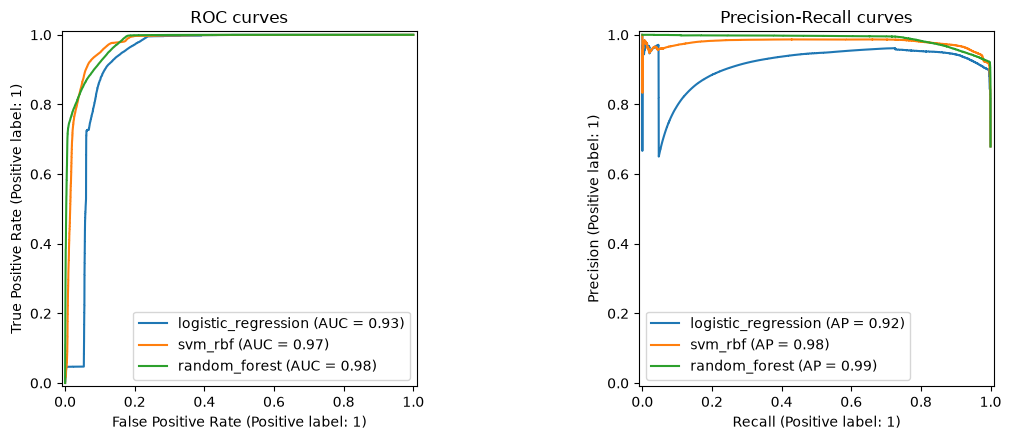

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, (y_te, _, y_score) in holdout.items():
    RocCurveDisplay.from_predictions(y_te, y_score, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_te, y_score, name=name, ax=axes[1])
axes[0].set_title("ROC curves")
axes[1].set_title("Precision-Recall curves")
plt.tight_layout()
plt.show()

## 8. SVM diagnostics on the 80/20 split

              precision    recall  f1-score   support

           0     0.9928    0.7435    0.8503     33690
           1     0.8918    0.9975    0.9417     71417

    accuracy                         0.9161    105107
   macro avg     0.9423    0.8705    0.8960    105107
weighted avg     0.9242    0.9161    0.9124    105107



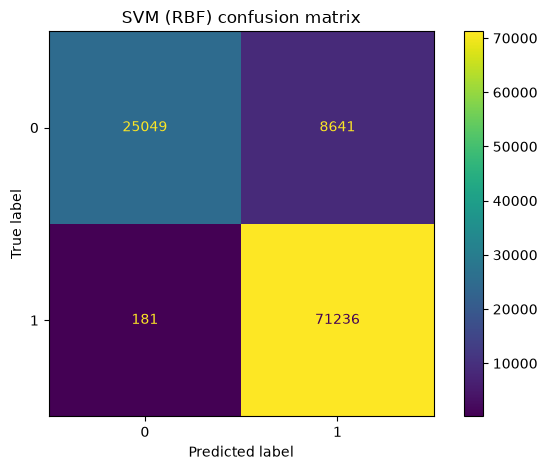

In [11]:
y_te, y_pred, y_score = holdout["svm_rbf"]
print(classification_report(y_te, y_pred, digits=4))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred)
plt.title("SVM (RBF) confusion matrix")
plt.tight_layout()
plt.show()

## 9. Log the evaluation run to DAGsHub MLflow

`src/train_svm.py` and `src/experiments.py` already log their own runs to the
`student_performance_baseline` experiment. This final cell logs a consolidated
summary so the notebook itself is traceable on the DAGsHub Experiments page.

In [12]:
setup_mlflow(experiment_name="student_performance_baseline")

with mlflow.start_run(run_name="notebook_validation_summary"):
    mlflow.log_params({
        "sample_size": SAMPLE_SIZE,
        "random_state": RANDOM_STATE,
        "splits": "0.2,0.3,0.4",
        "cv_folds": 5,
        "note": "consolidated summary from notebooks/02_svm_model_validation.ipynb",
    })
    mlflow.log_metrics({k: float(v) for k, v in holdout_metrics.items()})
    mlflow.log_metrics({f"cv_{k}": float(v) for k, v in cv_summary.items()})
    print("Logged notebook summary run to DAGsHub MLflow")

[MLflow] Connected to tracking URI: https://dagshub.com/suhaybfr/ML-ops.mlflow
[MLflow] Active Experiment: student_performance_baseline


Logged notebook summary run to DAGsHub MLflow


🏃 View run notebook_validation_summary at: https://dagshub.com/suhaybfr/ML-ops.mlflow/#/experiments/1/runs/c24cf2147e8441459f9f7da05f135479
🧪 View experiment at: https://dagshub.com/suhaybfr/ML-ops.mlflow/#/experiments/1
